# 11 - Treatment re-dating: snapshot year vs. STATUS_YR, with expansions

Notebook 02 dates each cell by the **first WDPA yearly snapshot (2017-2025) that covers it**; only cells already covered by the 2017 snapshot take the polygon's `STATUS_YR`. WDPA publishes new areas and boundary changes with a lag, so every cohort from 2018 on is dated by publication, not by legal designation.

A second problem is **expansions**. When an existing park grows, WDPA keeps the park's original `STATUS_YR` on the enlarged polygon: the Serranía de Chiribiquete record (WDPA 19984) still says 1989 after the July 2018 expansion (MADS Resolution 1256), which first appears in the Sept 2020 snapshot. A pure `STATUS_YR` rule would therefore date the 2018 expansion area 1989 and drop it from the treated group.

Four definitions are compared:

| Definition | Treatment year of a cell |
|---|---|
| **current (nb02)** | first snapshot year covering the cell; `STATUS_YR` only if first covered in 2017 |
| **A - STATUS_YR at first coverage** | `min(STATUS_YR, snapshot year)` of the polygons in the first snapshot covering the cell |
| **B - earliest STATUS_YR** | `min(STATUS_YR, snapshot year)` over polygons in any snapshot (also picks up later WDPA corrections of old parks) |
| **C - A with expansions** | as A, except cells added to a park that already existed in an earlier snapshot: those get the expansion's own year (legal date from `EXPANSION_LEGAL_YEARS` if known, otherwise the first snapshot showing the added area). The park's previous area keeps its previous year |

A park is identified across snapshots by `WDPAID` (2017-2024) or `SITE_ID` (2025, where WDPA renamed the field); the two match (e.g. Chiribiquete is 19984 in every snapshot). `STATUS_YR` outside 1900-2025 or after the snapshot year is ignored (snapshot year used instead), as in nb02. A cell counts as covered when a polygon overlaps it with positive area (nb02's `any` rule, EPSG:6933). Which cells are protected does not change; only their dates do. The overlay reproduces nb02's current dates **exactly** for all protected cells, so the definitions differ only in the dating rule.

**Part A** compares the definitions. **Part B** (added once a definition is chosen) compares the notebook-10 TWFE estimates, for the full 2001-2025 panel and for 2017 onwards. Nothing upstream is modified: everything is cached to new files.

In [1]:
from pathlib import Path
import sys
import time

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'notebooks').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

INTERMEDIATE_DIR = PROJECT_ROOT / 'data' / 'intermediate'
TABLE_DIR = PROJECT_ROOT / 'outputs' / 'tables'
FIG_DIR = PROJECT_ROOT / 'outputs' / 'figures'
print('Project root:', PROJECT_ROOT)

Project root: C:\Users\cpedr\OneDrive - Hertie School\PhD\Paper 2\paper2


## Configuration

In [2]:
RUN_TAG = '1km'
START_YEAR = 2001            # panel start; cohorts > START_YEAR are the in-window treated set (as in nb08)
PANEL_MAX_YEAR = 2025
SNAPSHOT_START_YEAR = 2017   # first WDPA yearly snapshot downloaded in nb02
STATUS_YEAR_BOUNDS = (1900, PANEL_MAX_YEAR)   # same bounds as nb02 (TREATMENT_YEAR_FLOOR = 1900)
AREA_CRS = 'EPSG:6933'                        # same as nb02

# Legal year of known expansions, by WDPA site id. Expansions not listed here are dated by the
# first snapshot that shows the added area (still lagged). Fill in more from
# outputs/tables/11_detected_expansions_1km.csv as legal dates are found.
EXPANSION_LEGAL_YEARS = {
    19984: 2018,   # Serranía de Chiribiquete NNP: MADS Resolution 1256, July 2018 (+1,486,676 ha)
}

OLD_LOOKUP_PATH = INTERMEDIATE_DIR / f'cell_treatment_lookup_{RUN_TAG}.parquet'
GRID_PATH = INTERMEDIATE_DIR / 'grid_geometry_1km_shp' / 'grid_geometry_1km.shp'
WDPA_PATH = INTERMEDIATE_DIR / 'wdpa_colombia_yearly_snapshots.parquet'
CENTROID_PATH = INTERMEDIATE_DIR / 'spatial_structure' / f'03_grid_centroids_{RUN_TAG}.parquet'
PAIRS_PATH = INTERMEDIATE_DIR / f'11_pa_cell_overlap_pairs_{RUN_TAG}.parquet'   # cached overlay (cell x polygon)
NEW_LOOKUP_PATH = INTERMEDIATE_DIR / f'cell_treatment_lookup_statusyr_{RUN_TAG}.parquet'
REBUILD_PAIRS = False   # True reruns the overlay (about 7-8 minutes)

DEFS = {
    'current': 'year_old',
    'A: STATUS_YR at first coverage': 'year_statusyr_first',
    'B: earliest STATUS_YR': 'year_statusyr_min',
    'C: A with expansions': 'year_statusyr_expansions',
}

## Overlay: which polygons overlap which cells

Only the 226,343 cells protected under the current lookup are overlaid (the same polygons cannot add or remove cells). Instead of nb02's clip-and-dissolve, which computes overlap areas that the `any` rule does not need, each polygon is tested against its candidate cells: cells strictly inside are kept directly (prepared geometry), and boundary cells are kept only if their interior overlaps the polygon (`relate` pattern `T********`, i.e. positive overlap area). Identical (park, `STATUS_YR`, geometry) rows repeated across snapshots are tested once, keeping their earliest snapshot. The result is one row per (cell, polygon) overlap, cached so the dating rules below can be changed without redoing the overlay.

In [3]:
old = pd.read_parquet(OLD_LOOKUP_PATH, columns=['cell_id', 'first_treat_year_protected_area'])
old = old[old['first_treat_year_protected_area'].notna()].rename(columns={'first_treat_year_protected_area': 'year_old'})
old['cell_id'] = old['cell_id'].astype('string')
print(f'Protected cells in the current lookup: {len(old):,}')

wdpa = gpd.read_parquet(WDPA_PATH, columns=['NAME', 'DESIG_ENG', 'WDPAID', 'SITE_ID', 'STATUS_YR', 'wdpa_snapshot_year', 'geometry'])
wdpa = wdpa[wdpa.geometry.notna() & (wdpa['wdpa_snapshot_year'] <= PANEL_MAX_YEAR)].copy()
wdpa['site_id'] = wdpa['WDPAID'].fillna(pd.to_numeric(wdpa['SITE_ID'], errors='coerce')).astype('Int64')
status = pd.to_numeric(wdpa['STATUS_YR'], errors='coerce').round()
status = status.where(status.between(*STATUS_YEAR_BOUNDS))
wdpa['status'] = status.where(status <= wdpa['wdpa_snapshot_year'])          # valid STATUS_YR, not after the snapshot
wdpa['treat_year'] = wdpa['status'].fillna(wdpa['wdpa_snapshot_year']).astype(int)
site_first_snapshot = wdpa.groupby('site_id')['wdpa_snapshot_year'].min()
site_names = wdpa.sort_values('wdpa_snapshot_year').groupby('site_id').agg(name=('NAME', 'first'), designation=('DESIG_ENG', 'first'))
print(f"WDPA rows: {len(wdpa):,}; sites: {wdpa['site_id'].nunique():,}; rows without a site id: {int(wdpa['site_id'].isna().sum())}")

def build_overlap_pairs():
    t0 = time.time()
    grid = gpd.read_file(GRID_PATH, engine='pyogrio')
    grid['cell_id'] = grid['cell_id'].astype('string')
    grid = grid[grid['cell_id'].isin(old['cell_id'])].to_crs(AREA_CRS).reset_index(drop=True)

    w = wdpa[['site_id', 'status', 'treat_year', 'wdpa_snapshot_year', 'geometry']].copy()
    w['_wkb'] = shapely.to_wkb(w.geometry.values)
    w = w.sort_values('wdpa_snapshot_year').drop_duplicates(subset=['site_id', 'treat_year', '_wkb']).drop(columns='_wkb')
    w['geometry'] = w.geometry.make_valid()
    w = w.to_crs(AREA_CRS).reset_index(drop=True)
    print(f'{len(grid):,} cells, {len(w):,} unique polygons  [{time.time() - t0:.0f}s]')

    polys = np.asarray(w.geometry.values, dtype=object)
    cell_geoms = np.asarray(grid.geometry.values, dtype=object)
    pi, ci = shapely.STRtree(cell_geoms).query(polys, predicate='intersects')
    order = np.argsort(pi, kind='stable')
    pi, ci = pi[order], ci[order]
    bounds = np.searchsorted(pi, np.arange(len(polys) + 1))
    ok = np.zeros(len(pi), dtype=bool)
    for k in range(len(polys)):
        a, b = bounds[k], bounds[k + 1]
        if a == b:
            continue
        poly = polys[k]
        shapely.prepare(poly)
        sub = cell_geoms[ci[a:b]]
        res = shapely.contains_properly(poly, sub)
        edge = ~res
        if edge.any():
            res[edge] = shapely.relate_pattern(poly, sub[edge], 'T********')
        ok[a:b] = res
        shapely.destroy_prepared(poly)
    print(f'{len(pi):,} candidate pairs, {int(ok.sum()):,} overlapping  [{time.time() - t0:.0f}s]')
    return pd.DataFrame({
        'cell_id': grid['cell_id'].to_numpy()[ci[ok]],
        'site_id': w['site_id'].to_numpy()[pi[ok]],
        'snap': w['wdpa_snapshot_year'].to_numpy()[pi[ok]].astype(int),
        'status': w['status'].to_numpy()[pi[ok]],
        'treat': w['treat_year'].to_numpy()[pi[ok]],
    })

if PAIRS_PATH.exists() and not REBUILD_PAIRS:
    pairs = pd.read_parquet(PAIRS_PATH)
    print('Loaded cached:', PAIRS_PATH.name)
else:
    pairs = build_overlap_pairs()
    pairs.to_parquet(PAIRS_PATH, index=False)
    print('Saved:', PAIRS_PATH)
pairs['cell_id'] = pairs['cell_id'].astype('string')
print(f'{len(pairs):,} cell-polygon overlaps, {pairs.cell_id.nunique():,} cells')

Protected cells in the current lookup: 226,343


WDPA rows: 12,270; sites: 1,924; rows without a site id: 0
Loaded cached: 11_pa_cell_overlap_pairs_1km.parquet


922,345 cell-polygon overlaps, 226,343 cells


## Dating rules

For every cell, take the polygons covering it in its **first** covering snapshot $s$:

* **current:** $s$, or the polygon's `STATUS_YR` when $s = 2017$
* **A:** each polygon's `min(STATUS_YR, s)`, minimum over the polygons
* **B:** `min(STATUS_YR, snapshot)` over polygons in any snapshot
* **C:** as A, but a polygon whose park already appeared in an earlier snapshot marks the cell as **added to an existing park**; its year is the legal expansion year if listed in `EXPANSION_LEGAL_YEARS`, otherwise $s$. When $s = 2017$ there is no earlier snapshot, so expansions before 2017 cannot be detected and keep the park's `STATUS_YR` (e.g. Chiribiquete's 2013 expansion stays dated 1989).

In [4]:
first = pairs.groupby('cell_id')['snap'].transform('min')
fp = pairs[pairs['snap'] == first].copy()          # polygons in each cell's first covering snapshot
fp['site_first_snap'] = fp['site_id'].map(site_first_snapshot)
fp['is_expansion'] = (fp['snap'] > SNAPSHOT_START_YEAR) & (fp['site_first_snap'] < fp['snap'])
legal = fp['site_id'].map(EXPANSION_LEGAL_YEARS)
fp['year_c'] = np.where(fp['is_expansion'], legal.fillna(fp['snap']), fp['treat']).astype(int)
fp['c_source'] = np.where(~fp['is_expansion'], 'STATUS_YR rule (as A)',
                  np.where(legal.notna(), 'expansion: legal year (manual)', 'expansion: first snapshot showing it'))

g = fp.groupby('cell_id').agg(first_snap=('snap', 'min'), status_first=('status', 'min'),
                              year_statusyr_first=('treat', 'min'), year_statusyr_expansions=('year_c', 'min'))
g['year_nb02_reproduced'] = np.where((g['first_snap'] == SNAPSHOT_START_YEAR) & g['status_first'].notna(),
                                     g['status_first'], g['first_snap']).astype(int)
g['year_statusyr_min'] = pairs.groupby('cell_id')['treat'].min().reindex(g.index)
# which branch set the C date (the polygon giving the minimum)
src = fp.sort_values('year_c').drop_duplicates('cell_id').set_index('cell_id')[['c_source', 'site_id']]
g = g.join(src.rename(columns={'site_id': 'c_site_id'}))
new = g.reset_index()
for col in ['year_statusyr_first', 'year_statusyr_min', 'year_statusyr_expansions', 'year_nb02_reproduced']:
    new[col] = new[col].astype(int)
new.drop(columns=['status_first']).to_parquet(NEW_LOOKUP_PATH, index=False)
print('Saved:', NEW_LOOKUP_PATH)

c = old.merge(new, on='cell_id', how='outer', indicator=True)
print(c['_merge'].value_counts().to_string())
c = c[c['_merge'] == 'both'].drop(columns='_merge')
c['year_old'] = c['year_old'].astype(int)
print(f"Validation - nb02 dates reproduced exactly: {int((c['year_old'] == c['year_nb02_reproduced']).sum()):,} of {len(c):,} cells")
print('\nDefinition C - source of each cell date:')
print(c['c_source'].value_counts().to_string())

Saved: C:\Users\cpedr\OneDrive - Hertie School\PhD\Paper 2\paper2\data\intermediate\cell_treatment_lookup_statusyr_1km.parquet
_merge
both          226343
left_only          0
right_only         0
Validation - nb02 dates reproduced exactly: 226,343 of 226,343 cells

Definition C - source of each cell date:
c_source
STATUS_YR rule (as A)                   207275
expansion: legal year (manual)           15095
expansion: first snapshot showing it      3973


### Detected expansions

Every (park, snapshot) in which an existing park gained cells, with the year definition C assigns. Small additions are often boundary re-digitising rather than legal expansions; they are listed so they can be checked. The CSV is the place to collect legal years for `EXPANSION_LEGAL_YEARS`.

In [5]:
exp = c[c['c_source'].str.startswith('expansion')]
detected = (exp.groupby(['c_site_id', 'first_snap', 'year_statusyr_expansions', 'c_source']).size()
            .reset_index(name='added_cells')
            .rename(columns={'c_site_id': 'site_id', 'first_snap': 'first_snapshot_showing_it', 'year_statusyr_expansions': 'year_assigned_C'}))
detected = detected.join(site_names, on='site_id')
detected['park_status_yr'] = detected['site_id'].map(wdpa.groupby('site_id')['status'].min())
detected['size_class'] = pd.cut(detected['added_cells'], [0, 9, 99, np.inf], labels=['<10 cells (likely re-digitising)', '10-99 cells', '100+ cells'])
detected = detected.sort_values('added_cells', ascending=False)
detected['legal_year_to_check'] = ''
cols = ['site_id', 'name', 'designation', 'park_status_yr', 'first_snapshot_showing_it', 'added_cells', 'size_class', 'year_assigned_C', 'c_source', 'legal_year_to_check']
display(detected[cols].head(25))
print(detected.groupby('size_class', observed=False).agg(expansions=('added_cells', 'size'), cells=('added_cells', 'sum')).to_string())
detected[cols].to_csv(TABLE_DIR / f'11_detected_expansions_{RUN_TAG}.csv', index=False)
print('Saved:', TABLE_DIR / f'11_detected_expansions_{RUN_TAG}.csv')

,site_id,name,designation,park_status_yr,first_snapshot_showing_it,added_cells,size_class,year_assigned_C,c_source,legal_year_to_check
33,19984,Serrania De Chiribiquete,Natural National Park,1989.0,2020,15094,100+ cells,2018,expansion: legal year (manual),
7,132,Sierra Nevada De Santa Marta,Natural National Park,1964.0,2024,1732,100+ cells,2024,expansion: first snapshot showing it,
3,131,Paramillo,Natural National Park,1977.0,2018,214,100+ cells,2018,expansion: first snapshot showing it,
81,555555844,Cuchilla Del San Juan,Integrated Management Regional District,2000.0,2024,211,100+ cells,2024,expansion: first snapshot showing it,
82,555555847,Serrania De Perija,Integrated Management Regional District,2011.0,2024,204,100+ cells,2024,expansion: first snapshot showing it,
49,303547,Rio Pure,Natural National Park,2002.0,2024,152,100+ cells,2024,expansion: first snapshot showing it,
2,130,Sierra De La Macarena,Natural National Park,1971.0,2018,149,100+ cells,2018,expansion: first snapshot showing it,
94,555635941,Vista Hermosa de Monquentiva,Park Natural Regional,2017.0,2024,105,100+ cells,2024,expansion: first snapshot showing it,
75,555555803,Corredor Biologico Guacharos Purace,Park Natural Regional,2007.0,2024,90,10-99 cells,2024,expansion: first snapshot showing it,
40,100719,Rio Mocoa,Forest Reserve Protectress National,1984.0,2025,75,10-99 cells,2025,expansion: first snapshot showing it,


                                  expansions  cells
size_class                                         
<10 cells (likely re-digitising)          76    214
10-99 cells                               30    993
100+ cells                                 8  17861
Saved: C:\Users\cpedr\OneDrive - Hertie School\PhD\Paper 2\paper2\outputs\tables\11_detected_expansions_1km.csv


## Part A - How different are the definitions?

Categories follow the nb08 convention: **in window** = treatment year after 2001 (the treated group); **pre-panel** = 2001 or earlier (excluded from both treated and controls).

* **unchanged** - same year (reported separately for in-window and pre-panel cells)
* **re-dated, stays in window** - earlier year, still a 2002+ cohort
* **moves to pre-panel** - in window under the current dating, 2001 or earlier under the alternative (under A and B: expansion cells inheriting an old park's `STATUS_YR`); these leave the treated group
* **pre-panel under both** - possibly re-dated, irrelevant for estimation

In [6]:
def categorise(y_old, y_new):
    in_old, in_new = y_old > START_YEAR, y_new > START_YEAR
    out = np.where((y_old == y_new) & in_old, 'unchanged (in window)',
          np.where(y_old == y_new, 'unchanged (pre-panel)',
          np.where(in_old & in_new, 're-dated, stays in window',
          np.where(in_old & ~in_new, 'moves to pre-panel',
          np.where(~in_old & in_new, 'moves into window', 'pre-panel under both (re-dated)')))))
    return pd.Series(out, index=y_old.index)

rows = []
for name, col in DEFS.items():
    y = c[col]
    rows.append({
        'definition': name,
        'in-window treated cells': int((y > START_YEAR).sum()),
        'pre-panel cells': int((y <= START_YEAR).sum()),
        'cells with a different year than current': int((y != c['year_old']).sum()),
        'cells with a later year (should be 0)': int((y > c['year_old']).sum()),
    })
summary = pd.DataFrame(rows).set_index('definition').T
display(summary)

cat_tables = {}
for name, col in list(DEFS.items())[1:]:
    cat = categorise(c['year_old'], c[col])
    shift = c['year_old'] - c[col]
    t = pd.DataFrame({'cells': cat.value_counts()})
    t['median shift (years)'] = shift.groupby(cat).median()
    t['% of current in-window cells'] = (100 * t['cells'] / (c['year_old'] > START_YEAR).sum()).round(1)
    cat_tables[name] = t
    c[f'cat_{col}'] = cat
cat_all = pd.concat(cat_tables, names=['definition', 'category'])
display(cat_all)
summary.to_csv(TABLE_DIR / f'11_redating_summary_{RUN_TAG}.csv')
cat_all.to_csv(TABLE_DIR / f'11_redating_categories_{RUN_TAG}.csv')

definition,current,A: STATUS_YR at first coverage,B: earliest STATUS_YR,C: A with expansions
in-window treated cells,103488,85307,83816,103335
pre-panel cells,122855,141036,142527,123008
cells with a different year than current,0,51764,98315,47790
cells with a later year (should be 0),0,0,0,0


cells  \
definition                     category                                  
A: STATUS_YR at first coverage unchanged (pre-panel)            122855   
                               unchanged (in window)             51724   
                               re-dated, stays in window         33583   
                               moves to pre-panel                18181   
B: earliest STATUS_YR          unchanged (pre-panel)             90156   
                               re-dated, stays in window         45944   
                               unchanged (in window)             37872   
                               pre-panel under both (re-dated)   32699   
                               moves to pre-panel                19672   
C: A with expansions           unchanged (pre-panel)            122855   
                               unchanged (in window)             55698   
                               re-dated, stays in window         47637   
                               moves to pre-panel                  153   

                                                                median shift (years)  \
definition                     category                                                
A: STATUS_YR at first coverage unchanged (pre-panel)                             0.0   
                               unchanged (in window)                             0.0   
                               re-dated, stays in window                         2.0   
                               moves to pre-panel                               31.0   
B: earliest STATUS_YR          unchanged (pre-panel)                             0.0   
                               re-dated, stays in window                         3.0   
                               unchanged (in window)                             0.0   
                               pre-panel under both (re-dated)                  11.0   
                               moves to pre-panel                               31.0   
C: A with expansions           unchanged (pre-panel)                             0.0   
                               unchanged (in window)                             0.0   
                               re-dated, stays in window                         2.0   
                               moves to pre-panel                               30.0   

                                                                % of current in-window cells  
definition                     category                                                       
A: STATUS_YR at first coverage unchanged (pre-panel)                                   118.7  
                               unchanged (in window)                                    50.0  
                               re-dated, stays in window                                32.5  
                               moves to pre-panel                                       17.6  
B: earliest STATUS_YR          unchanged (pre-panel)                                    87.1  
                               re-dated, stays in window                                44.4  
                               unchanged (in window)                                    36.6  
                               pre-panel under both (re-dated)                          31.6  
                               moves to pre-panel                                       19.0  
C: A with expansions           unchanged (pre-panel)                                   118.7  
                               unchanged (in window)                                    53.8  
                               re-dated, stays in window                                46.0  
                               moves to pre-panel                                        0.1

### Cohort sizes

Under the current dating, cells first covered in 2017 already use `STATUS_YR`, so cohorts 2002-2017 only change in definition B (later WDPA corrections) or when re-dated 2018+ cells land in them. Cohorts 2018-2025 are the snapshot-dated ones.

,current,A: STATUS_YR at first coverage,B: earliest STATUS_YR,C: A with expansions
cohort,,,,
2002,11294,11456,11454,11294
2003,93,96,96,96
2004,41,41,41,41
2005,1104,1213,6379,1135
2006,773,791,2061,780
2007,4207,4410,6429,4207
2008,2662,2679,5196,2672
2009,14394,14460,15291,14456
2010,1118,1174,326,1167


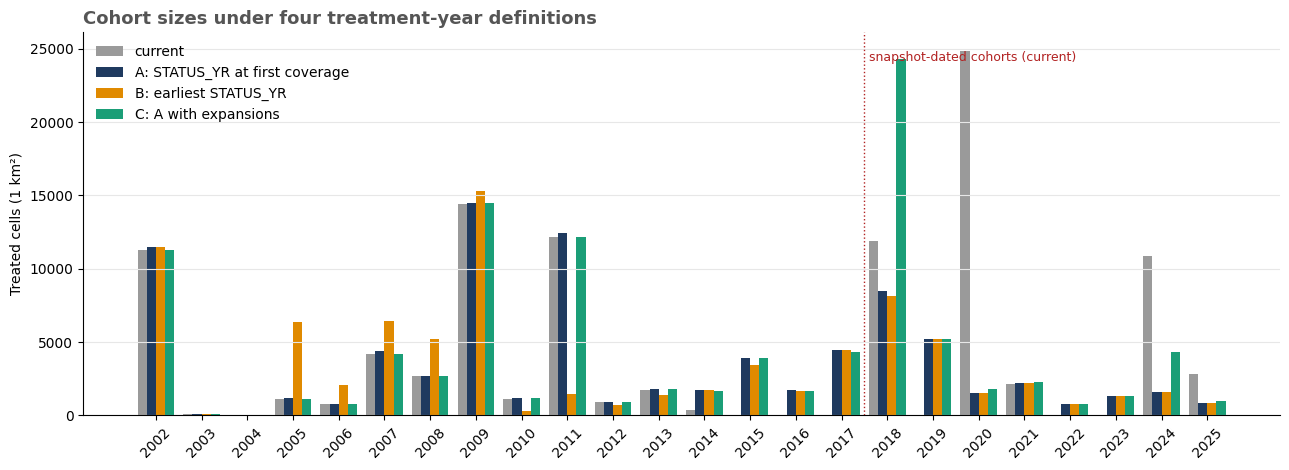

In [7]:
yrs = range(START_YEAR + 1, PANEL_MAX_YEAR + 1)
coh = pd.DataFrame({name: c.loc[c[col] > START_YEAR].groupby(col).size().reindex(yrs, fill_value=0) for name, col in DEFS.items()})
coh.index.name = 'cohort'
coh.loc['total'] = coh.sum()
display(coh)
coh.to_csv(TABLE_DIR / f'11_cohort_sizes_by_definition_{RUN_TAG}.csv')

plot = coh.drop(index='total')
fig, ax = plt.subplots(figsize=(13, 4.8))
x = np.arange(len(plot)); wd = 0.2
for i, (name, color) in enumerate(zip(DEFS, ['#9a9a9a', '#1f3a5f', '#e08a00', '#1b9e77'])):
    ax.bar(x + (i - 1.5) * wd, plot[name], width=wd, color=color, label=name)
cut = list(plot.index).index(SNAPSHOT_START_YEAR + 1) - 0.5
ax.axvline(cut, color='#b22222', linestyle=':', linewidth=1)
ax.text(cut + 0.1, ax.get_ylim()[1] * 0.95, 'snapshot-dated cohorts (current)', color='#b22222', fontsize=9, va='top')
ax.set_xticks(x); ax.set_xticklabels(plot.index, rotation=45)
ax.set_ylabel('Treated cells (1 km²)')
ax.set_title('Cohort sizes under four treatment-year definitions', loc='left', color='#555555', fontsize=13, weight='bold')
ax.grid(True, axis='y', color='#e7e7e7'); ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG_DIR / f'11_cohort_sizes_by_definition_{RUN_TAG}.png', dpi=220, bbox_inches='tight'); plt.show()

### Where cells move: current cohort x alternative cohort

Rows are the current cohort (2018+ individually, earlier cohorts pooled), columns the alternative cohort.

In [8]:
def bin_year(y):
    if y <= START_YEAR:
        return '<=2001 (pre-panel)'
    if y <= 2010:
        return '2002-2010'
    if y <= SNAPSHOT_START_YEAR:
        return f'2011-{SNAPSHOT_START_YEAR}'
    return str(y)
order = ['<=2001 (pre-panel)', '2002-2010', f'2011-{SNAPSHOT_START_YEAR}'] + [str(y) for y in range(SNAPSHOT_START_YEAR + 1, PANEL_MAX_YEAR + 1)]
old_bin = c['year_old'].map(bin_year)
for name, col in list(DEFS.items())[1:]:
    t = pd.crosstab(old_bin, c[col].map(bin_year))
    t = t.reindex(index=[o for o in order if o in t.index], columns=[o for o in order if o in t.columns], fill_value=0)
    print(f'\nRows: current cohort | Columns: {name}')
    display(t)
    t.to_csv(TABLE_DIR / f"11_transition_current_vs_{col}_{RUN_TAG}.csv")


Rows: current cohort | Columns: A: STATUS_YR at first coverage


year_statusyr_first,<=2001 (pre-panel),2002-2010,2011-2017,2018,2019,2020,2021,2022,2023,2024,2025
year_old,,,,,,,,,,,
<=2001 (pre-panel),122855,0,0,0,0,0,0,0,0,0,0
2002-2010,0,35686,0,0,0,0,0,0,0,0,0
2011-2017,0,0,15190,0,0,0,0,0,0,0,0
2018,655,216,11019,0,0,0,0,0,0,0,0
2019,2,0,7,0,0,0,0,0,0,0,0
2020,15367,3,292,8347,870,0,0,0,0,0,0
2021,0,0,0,69,1943,107,0,0,0,0,0
2024,2055,392,374,2,2392,1308,2235,761,1346,0,0
2025,102,23,90,54,0,147,0,0,0,1586,848



Rows: current cohort | Columns: B: earliest STATUS_YR


year_statusyr_min,<=2001 (pre-panel),2002-2010,2011-2017,2018,2019,2020,2021,2022,2023,2024,2025
year_old,,,,,,,,,,,
<=2001 (pre-panel),122855,0,0,0,0,0,0,0,0,0,0
2002-2010,297,35389,0,0,0,0,0,0,0,0,0
2011-2017,805,10804,3581,0,0,0,0,0,0,0,0
2018,699,657,10534,0,0,0,0,0,0,0,0
2019,2,0,7,0,0,0,0,0,0,0,0
2020,15712,7,290,8000,870,0,0,0,0,0,0
2021,0,1,0,69,1946,103,0,0,0,0,0
2024,2055,392,374,2,2392,1308,2235,761,1346,0,0
2025,102,23,90,54,0,147,0,0,0,1586,848



Rows: current cohort | Columns: C: A with expansions


year_statusyr_expansions,<=2001 (pre-panel),2002-2010,2011-2017,2018,2019,2020,2021,2022,2023,2024,2025
year_old,,,,,,,,,,,
<=2001 (pre-panel),122855,0,0,0,0,0,0,0,0,0,0
2002-2010,0,35686,0,0,0,0,0,0,0,0,0
2011-2017,0,0,15190,0,0,0,0,0,0,0,0
2018,12,131,10933,814,0,0,0,0,0,0,0
2019,0,0,0,0,9,0,0,0,0,0,0
2020,122,3,221,23450,870,213,0,0,0,0,0
2021,0,0,0,18,1943,107,51,0,0,0,0
2024,19,28,7,1,2392,1312,2236,761,1348,2761,0
2025,0,0,89,54,0,147,0,0,0,1586,974


### Treatment status per cell-year

What the TWFE regression sees is $D_{it}$. For each alternative and window: the current number of treated cell-years with $D_{it}=1$, the cell-years that switch from 0 to 1 (cells treated earlier), and the cell-years that leave the in-window sample (cells that become pre-panel). Full panel (2001-2025) and 2017 onwards.

In [9]:
def dit_changes(y_old, y_new, y0):
    n_years = PANEL_MAX_YEAR + 1 - y0
    in_old, in_new = y_old > START_YEAR, y_new > START_YEAR
    d1_old = np.clip(PANEL_MAX_YEAR + 1 - np.maximum(y_old[in_old].to_numpy(), y0), 0, None).sum()
    stay = in_old & in_new
    lo = np.maximum(y_new[stay].to_numpy(), y0)
    hi = np.minimum(y_old[stay].to_numpy(), PANEL_MAX_YEAR + 1)
    switched = np.clip(hi - lo, 0, None).sum()
    leaving = int((in_old & ~in_new).sum()) * n_years
    return {'current D=1 cell-years': int(d1_old), 'cell-years switching D 0->1': int(switched),
            'switching as % of current D=1': round(100 * switched / d1_old, 1),
            'cell-years leaving the sample': int(leaving)}

dit = pd.DataFrame({
    (name, f'{y0}-{PANEL_MAX_YEAR}'): dit_changes(c['year_old'], c[col], y0)
    for name, col in list(DEFS.items())[1:] for y0 in (START_YEAR, SNAPSHOT_START_YEAR)
})
display(dit)
dit.to_csv(TABLE_DIR / f'11_dit_changes_by_definition_{RUN_TAG}.csv')

A: STATUS_YR at first coverage            \
                                                   2001-2025 2017-2025   
current D=1 cell-years                             1205197.0  737516.0   
cell-years switching D 0->1                          92201.0   69640.0   
switching as % of current D=1                            7.7       9.4   
cell-years leaving the sample                       454525.0  163629.0   

                              B: earliest STATUS_YR            \
                                          2001-2025 2017-2025   
current D=1 cell-years                    1205197.0  737516.0   
cell-years switching D 0->1                148295.0   68914.0   
switching as % of current D=1                  12.3       9.3   
cell-years leaving the sample              491800.0  177048.0   

                              C: A with expansions            
                                         2001-2025 2017-2025  
current D=1 cell-years                   1205197.0  737516.0  
cell-years switching D 0->1               109095.0   94001.0  
switching as % of current D=1                  9.1      12.7  
cell-years leaving the sample               3825.0    1377.0

### Which protected areas drive the changes

Each re-dated in-window cell is matched by centroid to a polygon whose `STATUS_YR` equals its new year, searching snapshots from the earliest on. Cells straddling a boundary may stay unmatched.

In [10]:
cent = pd.read_parquet(CENTROID_PATH, columns=['cell_id', 'centroid_lon', 'centroid_lat'])
cent['cell_id'] = cent['cell_id'].astype('string')
wn = gpd.read_parquet(WDPA_PATH, columns=['NAME', 'STATUS_YR', 'DESIG_ENG', 'wdpa_snapshot_year', 'geometry'])
wn['STATUS_YR'] = pd.to_numeric(wn['STATUS_YR'], errors='coerce')
wn = wn.sort_values('wdpa_snapshot_year')

def drivers_for(col):
    ch = c[(c['year_old'] > START_YEAR) & (c[col] != c['year_old'])].merge(cent, on='cell_id', how='left').reset_index(drop=True)
    if col == 'year_statusyr_expansions':
        # C records which park set each date, so name directly by site id
        nm = ch['c_site_id'].map(site_names['name']).fillna('(unknown)') + ' (' + ch['c_site_id'].map(site_names['designation']).fillna('') + ')'
        ch['protected_area'] = nm + ' | ' + ch['c_source']
        return (ch.groupby(['protected_area', 'year_old', col, f'cat_{col}']).size()
                .reset_index(name='cells').rename(columns={col: 'year_new', f'cat_{col}': 'category'})
                .sort_values('cells', ascending=False))
    names = np.array([''] * len(ch), dtype=object)
    x, y, yn = ch['centroid_lon'].to_numpy(), ch['centroid_lat'].to_numpy(), ch[col].to_numpy()
    for r in wn[wn['STATUS_YR'].isin(np.unique(yn))].itertuples():
        idx = np.where((names == '') & (yn == r.STATUS_YR))[0]
        if len(idx) == 0 or r.geometry is None:
            continue
        inside = shapely.contains_xy(r.geometry, x[idx], y[idx])
        names[idx[inside]] = f'{r.NAME} ({r.DESIG_ENG}; snapshot {r.wdpa_snapshot_year})'
    ch['protected_area'] = np.where(names == '', '(not matched by centroid)', names)
    return (ch.groupby(['protected_area', 'year_old', col, f'cat_{col}']).size()
            .reset_index(name='cells').rename(columns={col: 'year_new', f'cat_{col}': 'category'})
            .sort_values('cells', ascending=False))

for name, col in list(DEFS.items())[1:]:
    d = drivers_for(col)
    print(f'\n{name}: top protected areas behind the changes')
    display(d.head(20))
    d.to_csv(TABLE_DIR / f'11_redating_drivers_{col}_{RUN_TAG}.csv', index=False)


A: STATUS_YR at first coverage: top protected areas behind the changes


,protected_area,year_old,year_new,category,cells
600,Serrania de Chiribiquete (National Natural Par...,2020,1989,moves to pre-panel,14655
196,Cinaruco (Integrated Management National Distr...,2020,2018,"re-dated, stays in window",3375
612,Sierra Nevada de Santa Marta (National Natural...,2024,1964,moves to pre-panel,1593
202,Complejo Cenagoso de Zapatosa (Integrated Mana...,2024,2019,"re-dated, stays in window",1439
50,(not matched by centroid),2020,2018,"re-dated, stays in window",1417
25,(not matched by centroid),2018,2015,"re-dated, stays in window",1250
315,Encanto de los manglares del Bajo Baudo (Integ...,2018,2017,"re-dated, stays in window",1177
485,Miraflores Picachos (Regional Natural Parks; s...,2020,2018,"re-dated, stays in window",1010
27,(not matched by centroid),2018,2017,"re-dated, stays in window",964
119,Bajo Cauca Nechí (Integrated Management Region...,2025,2024,"re-dated, stays in window",777



B: earliest STATUS_YR: top protected areas behind the changes


,protected_area,year_old,year_new,category,cells
693,Serrania de Chiribiquete (National Natural Par...,2020,1989,moves to pre-panel,14655
702,Serrania de los Yariguies (Integrated Manageme...,2011,2005,"re-dated, stays in window",4113
252,Cinaruco (Integrated Management National Distr...,2020,2018,"re-dated, stays in window",3375
718,Sierra Nevada de Santa Marta (National Natural...,2024,1964,moves to pre-panel,1593
258,Complejo Cenagoso de Zapatosa (Integrated Mana...,2024,2019,"re-dated, stays in window",1439
98,(not matched by centroid),2020,2018,"re-dated, stays in window",1357
627,Paramos de Guantiva y la Rusia (Integrated Man...,2011,2008,"re-dated, stays in window",1256
386,Encanto de los manglares del Bajo Baudo (Integ...,2018,2017,"re-dated, stays in window",1177
72,(not matched by centroid),2018,2015,"re-dated, stays in window",1137
568,Miraflores Picachos (Regional Natural Parks; s...,2020,2018,"re-dated, stays in window",1010



C: A with expansions: top protected areas behind the changes


,protected_area,year_old,year_new,category,cells
872,Serrania De Chiribiquete (Natural National Par...,2020,2018,"re-dated, stays in window",15094
136,Cinaruco (Integrated Management National Distr...,2020,2018,"re-dated, stays in window",3606
144,Complejo Cenagoso de Zapatosa (Integrated Mana...,2024,2019,"re-dated, stays in window",1586
345,Encanto de los manglares del Bajo Baudo (Integ...,2018,2017,"re-dated, stays in window",1309
698,Miraflores Picachos (Regional Natural Parks) |...,2020,2018,"re-dated, stays in window",1164
69,Bosque Seco del Occidente Antioqueño (Integrat...,2024,2021,"re-dated, stays in window",1006
38,Bajo Cauca Nechí (Integrated Management Region...,2025,2024,"re-dated, stays in window",895
880,Serranía de Manacacías (National Natural Park)...,2024,2023,"re-dated, stays in window",786
182,Distrito Regional de Manejo Integrado Paramo d...,2020,2019,"re-dated, stays in window",540
181,Distrito Regional de Manejo Integrado Bosque S...,2020,2018,"re-dated, stays in window",510


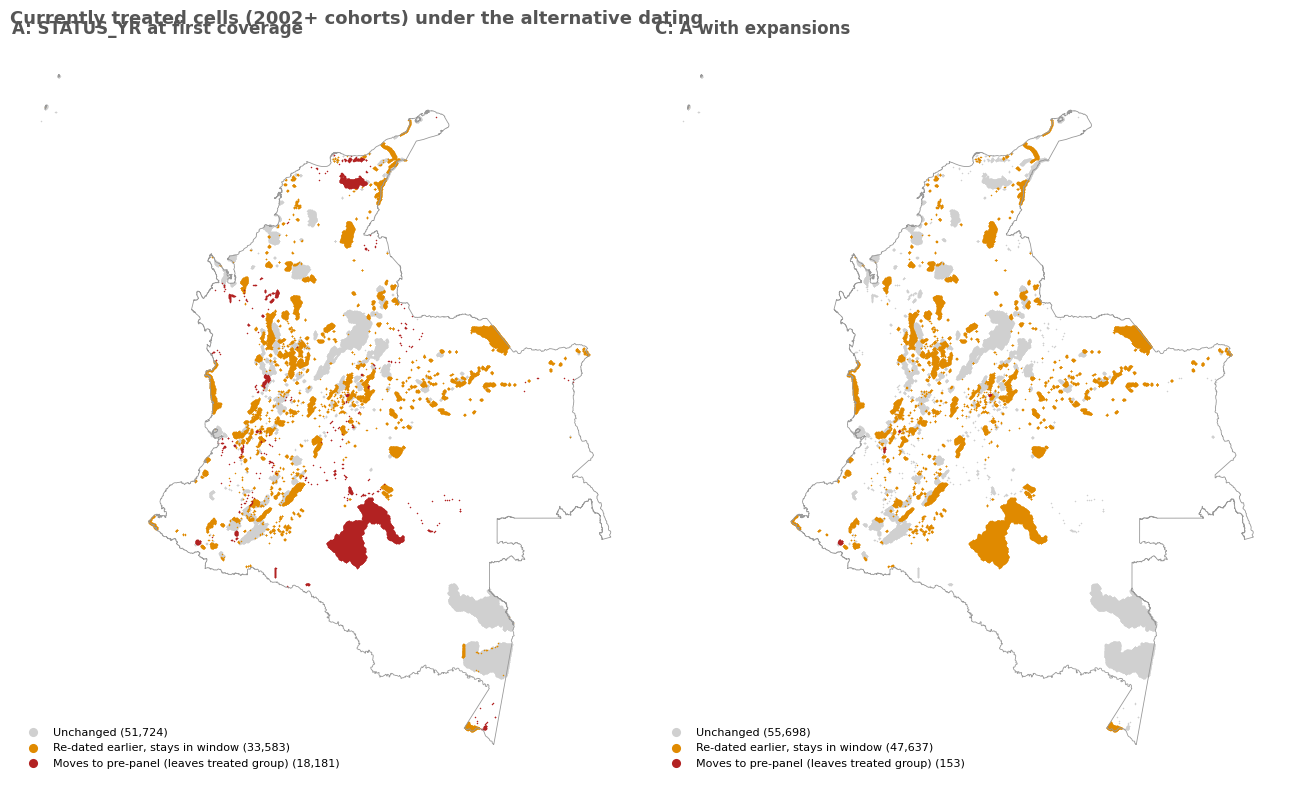

In [11]:
# Map of the changes, definitions A and C
try:
    outline = gpd.read_file(PROJECT_ROOT / 'data' / 'raw' / 'boundaries' / 'departamentos' / 'Departamentos_Diciembre_2025_shp').to_crs('EPSG:4326').dissolve().boundary
except Exception as exc:
    outline = None
    print('Outline not loaded:', exc)
m = c[c['year_old'] > START_YEAR].merge(cent, on='cell_id', how='left')
fig, axes = plt.subplots(1, 2, figsize=(13, 8))
for ax, (name, col) in zip(axes, [(k, v) for k, v in DEFS.items() if k.startswith(('A', 'C'))]):
    if outline is not None:
        outline.plot(ax=ax, color='#999999', linewidth=0.6)
    for cat, colr, lab in [('unchanged (in window)', '#d0d0d0', 'Unchanged'),
                           ('re-dated, stays in window', '#e08a00', 'Re-dated earlier, stays in window'),
                           ('moves to pre-panel', '#b22222', 'Moves to pre-panel (leaves treated group)')]:
        s = m[m[f'cat_{col}'] == cat]
        ax.scatter(s['centroid_lon'], s['centroid_lat'], s=1.2, color=colr, linewidths=0, rasterized=True, label=f'{lab} ({len(s):,})')
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_title(name, loc='left', color='#555555', fontsize=12, weight='bold')
    ax.legend(loc='lower left', frameon=False, fontsize=8, markerscale=6)
fig.suptitle('Currently treated cells (2002+ cohorts) under the alternative dating', x=0.01, ha='left', color='#555555', fontsize=13, weight='bold')
fig.tight_layout(); fig.savefig(FIG_DIR / f'11_redating_map_{RUN_TAG}.png', dpi=220, bbox_inches='tight'); plt.show()

## Part B - TWFE estimates: current dating vs. definition C

Definition **C** (STATUS_YR at first coverage, with expansions as their own cohort) is the chosen re-dating. This part re-estimates the four notebook-10 TWFE models with `pyfixest` under both datings and in two windows:

$$\text{loss}_{it} = \beta\, D_{it} + \alpha_i + \gamma_t + \varepsilon_{it}, \qquad D_{it}=\mathbf 1[t \ge g_i]$$

| | **Only newly added PAs** | **All PA cells** |
|---|---|---|
| treated | cells whose treatment year is after the window start (they switch on inside the window) | the same, **plus** cells protected before the window start (D = 1 in every year) |
| **No buffer** | controls = every never-treated cell | same |
| **35 km buffer** | controls = never-treated cells always more than 35 km from any protected cell | same |

* **Window 2001-2025**: identical to notebook 10 (cohorts 2002-2025 are "newly added"; cells protected before 2001 are the always-treated group). Under the current dating it must reproduce notebook 10's coefficients exactly.
* **Window 2017-2025**: the years covered by WDPA snapshots. "Newly added" = cohorts 2018-2025; cells protected before 2017 are always-treated within the window and enter only the "all PA cells" models.
* Following nb08/nb10, cells whose treatment year equals the window start are in neither group (treated from the first observed year, so not a switcher, and not protected before the window either).

Standard errors are clustered by cell and by 35 km spatial blocks (as in nb10); the block-clustered SE is the one used for significance. Treated cells stay the same set under both datings (except the 153 cells C moves before 2001), so differences come from **when** $D_{it}$ switches on.

In [12]:
import pyfixest as pf
import pyarrow.parquet as pq
from scipy.spatial import cKDTree

OUTCOME_COL = 'loss_m2'
MAIN_BUFFER_KM = 35
BLOCK_KM = 35
WINDOWS = [START_YEAR, SNAPSHOT_START_YEAR]          # 2001-2025 and 2017-2025
PANEL_PATH = INTERMEDIATE_DIR / f'panel_treatment_{RUN_TAG}.parquet'
EXPOSURE_PATH = INTERMEDIATE_DIR / f'06_nearest_treated_exposure_{RUN_TAG}.parquet'
NB10_PATH = TABLE_DIR / f'10_twfe_vs_cs_comparison_{RUN_TAG}.csv'
DATINGS = {'current': 'year_old', 'C': 'year_statusyr_expansions'}

panel = pd.read_parquet(PANEL_PATH, columns=['cell_id', 'year', OUTCOME_COL, 'first_treat_year'])
panel['year'] = panel['year'].astype('int16')
panel = panel[panel['year'] >= START_YEAR].reset_index(drop=True)
panel[OUTCOME_COL] = panel[OUTCOME_COL].astype('float32')
panel['cell_int'], cell_uniques = pd.factorize(panel['cell_id'])
panel['cell_int'] = panel['cell_int'].astype('int32')

cells = panel.drop_duplicates('cell_int').sort_values('cell_int')[['cell_int', 'cell_id', 'first_treat_year']].reset_index(drop=True)
cells['cell_id'] = cells['cell_id'].astype('string')
panel = panel.drop(columns=['cell_id', 'first_treat_year'])
cells = cells.merge(c[['cell_id', 'year_old', 'year_statusyr_expansions']], on='cell_id', how='left')
cells['never'] = cells['first_treat_year'].isna()
assert (cells.loc[~cells['never'], 'year_old'].astype(int) == cells.loc[~cells['never'], 'first_treat_year'].astype(int)).all(), 'panel and lookup disagree'
for col in DATINGS.values():
    cells[col] = cells[col].fillna(0).astype(int)                  # 0 = never treated
print(f"Panel: {len(panel):,} rows, {len(cells):,} cells, {int(cells['never'].sum()):,} never treated")

cent_xy = pd.read_parquet(CENTROID_PATH, columns=['cell_id', 'centroid_x_m', 'centroid_y_m'])
cent_xy['cell_id'] = cent_xy['cell_id'].astype('string')
cells = cells.merge(cent_xy, on='cell_id', how='left')
block_m = BLOCK_KM * 1000.0
bx = np.floor(cells['centroid_x_m'] / block_m).fillna(-1).astype('int64')
by = np.floor(cells['centroid_y_m'] / block_m).fillna(-1).astype('int64')
cells['block'] = pd.factorize(bx * 100_000 + by)[0].astype('int32')

Panel: 29,000,450 rows, 1,160,018 cells, 933,675 never treated


### Clean controls under C

A never-treated cell is a clean control if its distance to the nearest protected cell stays above 35 km in every year. Treatment is absorbing and the set of cells protected by 2025 is the same under both datings, so this minimum is the distance to the nearest of the 226,343 protected cells, whichever dating is used. It is recomputed here and checked against notebook 06's exposure file (2025, where every protected cell is already treated).

In [13]:
prot = ~cells['never'].to_numpy()
xy = cells[['centroid_x_m', 'centroid_y_m']].to_numpy(dtype=float)
dist_km, _ = cKDTree(xy[prot]).query(xy, k=1)
cells['min_dist_km'] = np.where(cells['never'], dist_km / 1000.0, np.nan)

exp25 = pq.read_table(EXPOSURE_PATH, columns=['cell_id', 'year', 'nearest_treated_distance_km'], filters=[('year', '==', PANEL_MAX_YEAR)]).to_pandas()
exp25['cell_id'] = exp25['cell_id'].astype('string')
chk = cells.loc[cells['never'], ['cell_id', 'min_dist_km']].merge(exp25, on='cell_id', how='left')
same_side = ((chk['min_dist_km'] > MAIN_BUFFER_KM) == (chk['nearest_treated_distance_km'] > MAIN_BUFFER_KM))
print(f"Never-treated cells: {len(chk):,}; max |difference| vs nb06 (km): {np.nanmax(np.abs(chk['min_dist_km'] - chk['nearest_treated_distance_km'])):.6f}")
print(f"Same clean-control status as nb06: {int(same_side.sum()):,} of {len(chk):,}")
print(f"Clean controls (> {MAIN_BUFFER_KM} km): {int((cells['min_dist_km'] > MAIN_BUFFER_KM).sum()):,}")

Never-treated cells: 933,675; max |difference| vs nb06 (km): 0.000000
Same clean-control status as nb06: 933,675 of 933,675
Clean controls (> 35 km): 264,952


### Estimation

In [14]:
MODEL_SPECS = [
    {'key': 'new_nobuffer', 'treatment': 'Newly added PAs only', 'buffer_km': None, 'include_pre': False},
    {'key': 'new_buffer', 'treatment': 'Newly added PAs only', 'buffer_km': MAIN_BUFFER_KM, 'include_pre': False},
    {'key': 'all_nobuffer', 'treatment': 'All PA cells', 'buffer_km': None, 'include_pre': True},
    {'key': 'all_buffer', 'treatment': 'All PA cells', 'buffer_km': MAIN_BUFFER_KM, 'include_pre': True},
]

def stars(p):
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else '.' if p < 0.1 else ''

never = cells['never'].to_numpy()
clean = (cells['min_dist_km'] > MAIN_BUFFER_KM).to_numpy()
block_by_cell = cells['block'].to_numpy()
year_arr = panel['year'].to_numpy()
cell_arr = panel['cell_int'].to_numpy()

rows = []
for w0 in WINDOWS:
    in_window = year_arr >= w0
    for dating, col in DATINGS.items():
        g = cells[col].to_numpy()
        new_treated = g > w0
        pre_treated = (g > 0) & (g < w0)
        for spec in MODEL_SPECS:
            ctrl = never if spec['buffer_km'] is None else never & clean
            keep = new_treated | ctrl | (pre_treated if spec['include_pre'] else False)
            sel = in_window & keep[cell_arr]
            df = pd.DataFrame({'cell_int': cell_arr[sel], 'year': year_arr[sel].astype('int32'), OUTCOME_COL: panel[OUTCOME_COL].to_numpy()[sel]})
            gi = g[df['cell_int'].to_numpy()]
            df['D'] = ((gi > 0) & (df['year'].to_numpy() >= gi)).astype('int8')
            df['block'] = block_by_cell[df['cell_int'].to_numpy()]

            fit = pf.feols(f'{OUTCOME_COL} ~ D | cell_int + year', data=df, vcov={'CRV1': 'cell_int'})
            b, se_c, p_c = float(fit.coef()['D']), float(fit.se()['D']), float(fit.pvalue()['D'])
            fit.vcov({'CRV1': 'block'})
            se_b, p_b = float(fit.se()['D']), float(fit.pvalue()['D'])
            ctrl_rows = ctrl[df['cell_int'].to_numpy()]
            ctrl_mean = float(df.loc[ctrl_rows, OUTCOME_COL].mean())
            rows.append({
                'window': f'{w0}-{PANEL_MAX_YEAR}', 'dating': dating, 'model': spec['key'], 'treatment': spec['treatment'],
                'buffer_km': 0 if spec['buffer_km'] is None else spec['buffer_km'],
                'coef': b, 'se_cell': se_c, 'p_cell': p_c, 'se_block35km': se_b, 'p_block35km': p_b, 'sig_block': stars(p_b),
                'pct_of_control_mean': 100 * b / ctrl_mean if ctrl_mean else np.nan,
                'n_obs': len(df), 'n_switcher_cells': int(new_treated[np.unique(df['cell_int'])].sum()),
                'n_always_treated_cells': int(pre_treated[np.unique(df['cell_int'])].sum()) if spec['include_pre'] else 0,
                'n_control_cells': int(ctrl[np.unique(df['cell_int'])].sum()),
            })
            print(f"{w0}-{PANEL_MAX_YEAR} | {dating:<7} | {spec['key']:<12} beta={b:>9.1f}  se(block)={se_b:>7.1f} {stars(p_b):<3} N={len(df):,}")
            del df, fit

twfe_redating = pd.DataFrame(rows)
twfe_redating.to_csv(TABLE_DIR / f'11_twfe_current_vs_C_{RUN_TAG}.csv', index=False)
print('Saved:', TABLE_DIR / f'11_twfe_current_vs_C_{RUN_TAG}.csv')

2001-2025 | current | new_nobuffer beta=   -308.3  se(block)=  107.4 **  N=25,929,075


2001-2025 | current | new_buffer   beta=   -351.7  se(block)=  147.0 *   N=9,211,000


2001-2025 | current | all_nobuffer beta=   -314.6  se(block)=  104.8 **  N=28,998,325


2001-2025 | current | all_buffer   beta=   -355.5  se(block)=  128.5 **  N=12,280,250


2001-2025 | C       | new_nobuffer beta=   -353.3  se(block)=  108.5 **  N=25,925,250


...

2017-2025 | current | all_buffer   beta=    201.8  se(block)=  123.3     N=4,421,655


2017-2025 | C       | new_nobuffer beta=    597.3  se(block)=  162.3 *** N=8,772,498


2017-2025 | C       | new_buffer   beta=    341.8  se(block)=  192.5 .   N=2,753,991


2017-2025 | C       | all_nobuffer beta=    506.2  se(block)=  156.5 **  N=10,401,183


2017-2025 | C       | all_buffer   beta=    218.8  se(block)=  163.2     N=4,382,676
Saved: C:\Users\cpedr\OneDrive - Hertie School\PhD\Paper 2\paper2\outputs\tables\11_twfe_current_vs_C_1km.csv


### Validation against notebook 10, and side-by-side comparison

In [15]:
if NB10_PATH.exists():
    nb10 = pd.read_csv(NB10_PATH)
    nb10 = nb10[nb10['estimator'].str.startswith('TWFE')][['model', 'coef', 'se_block35km']].rename(columns={'coef': 'coef_nb10', 'se_block35km': 'se_block_nb10'})
    v = twfe_redating[(twfe_redating['window'] == f'{START_YEAR}-{PANEL_MAX_YEAR}') & (twfe_redating['dating'] == 'current')].merge(nb10, on='model')
    v['abs_diff'] = (v['coef'] - v['coef_nb10']).abs()
    display(v[['model', 'coef', 'coef_nb10', 'abs_diff', 'se_block35km', 'se_block_nb10']].round(3))
else:
    print('nb10 table not found:', NB10_PATH)

fmt = twfe_redating.assign(cell=lambda d: d['coef'].map('{:,.1f}'.format) + d['sig_block'] + ' (' + d['se_block35km'].map('{:,.1f}'.format) + ')')
side = fmt.pivot_table(index=['window', 'model'], columns='dating', values='cell', aggfunc='first')[['current', 'C']]
num = twfe_redating.pivot_table(index=['window', 'model'], columns='dating', values='coef')
side['change in beta (C - current)'] = (num['C'] - num['current']).map('{:+,.1f}'.format)
side['change (%)'] = (100 * (num['C'] - num['current']) / num['current'].abs()).map('{:+.1f}%'.format)
side = side.reindex([(w, s['key']) for w in [f'{y}-{PANEL_MAX_YEAR}' for y in WINDOWS] for s in MODEL_SPECS])
display(side)
side.to_csv(TABLE_DIR / f'11_twfe_current_vs_C_side_by_side_{RUN_TAG}.csv')

counts = twfe_redating.pivot_table(index=['window', 'model'], columns='dating', values=['n_switcher_cells', 'n_always_treated_cells', 'n_control_cells', 'n_obs'], aggfunc='first')
display(counts.reindex(side.index))

,model,coef,coef_nb10,abs_diff,se_block35km,se_block_nb10
0,new_nobuffer,-308.308,-308.308,0.0,107.360,107.360
1,new_buffer,-351.734,-351.734,0.0,146.975,146.975
2,all_nobuffer,-314.632,-314.632,0.0,104.764,104.764
3,all_buffer,-355.530,-355.530,0.0,128.517,128.517


dating                           current                  C  \
window    model                                               
2001-2025 new_nobuffer  -308.3** (107.4)   -353.3** (108.5)   
          new_buffer     -351.7* (147.0)    -389.1* (153.5)   
          all_nobuffer  -314.6** (104.8)  -357.1*** (105.9)   
          all_buffer    -355.5** (128.5)   -388.5** (133.9)   
2017-2025 new_nobuffer  475.6*** (125.8)   597.3*** (162.3)   
          new_buffer      285.9* (142.1)     341.8. (192.5)   
          all_nobuffer  412.1*** (121.4)    506.2** (156.5)   
          all_buffer       201.8 (123.3)      218.8 (163.2)   

dating                 change in beta (C - current) change (%)  
window    model                                                 
2001-2025 new_nobuffer                        -45.0     -14.6%  
          new_buffer                          -37.4     -10.6%  
          all_nobuffer                        -42.5     -13.5%  
          all_buffer                          -33.0      -9.3%  
2017-2025 new_nobuffer                       +121.7     +25.6%  
          new_buffer                          +55.9     +19.5%  
          all_nobuffer                        +94.0     +22.8%  
          all_buffer                          +17.0      +8.4%

n_always_treated_cells         n_control_cells          \
dating                                      C current               C current   
window    model                                                                 
2001-2025 new_nobuffer                      0       0          933675  933675   
          new_buffer                        0       0          264952  264952   
          all_nobuffer                 122923  122770          933675  933675   
          all_buffer                   122923  122770          264952  264952   
2017-2025 new_nobuffer                      0       0          933675  933675   
          new_buffer                        0       0          264952  264952   
          all_nobuffer                 180965  173731          933675  933675   
          all_buffer                   180965  173731          264952  264952   

                           n_obs           n_switcher_cells          
dating                         C   current                C current  
window    model                                                      
2001-2025 new_nobuffer  25925250  25929075           103335  103488  
          new_buffer     9207175   9211000           103335  103488  
          all_nobuffer  28998325  28998325           103335  103488  
          all_buffer    12280250  12280250           103335  103488  
2017-2025 new_nobuffer   8772498   8876583            41047   52612  
          new_buffer     2753991   2858076            41047   52612  
          all_nobuffer  10401183  10440162            41047   52612  
          all_buffer     4382676   4421655            41047   52612

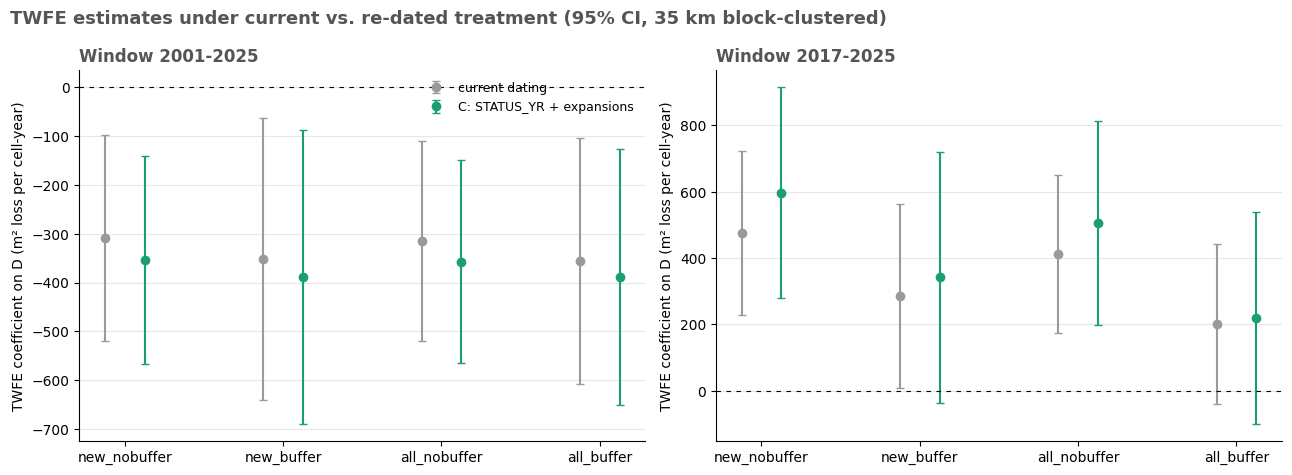

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=False)
colors = {'current': '#9a9a9a', 'C': '#1b9e77'}
labels = [s['key'] for s in MODEL_SPECS]
for ax, w0 in zip(axes, WINDOWS):
    sub = twfe_redating[twfe_redating['window'] == f'{w0}-{PANEL_MAX_YEAR}']
    for j, (dating, colr) in enumerate(colors.items()):
        d = sub[sub['dating'] == dating].set_index('model').reindex(labels)
        x = np.arange(len(labels)) + (j - 0.5) * 0.25
        ax.errorbar(x, d['coef'], yerr=1.96 * d['se_block35km'], fmt='o', color=colr, ecolor=colr, capsize=3, markersize=6,
                    label='current dating' if dating == 'current' else 'C: STATUS_YR + expansions')
    ax.axhline(0, color='black', linewidth=0.8, linestyle=(0, (4, 5)))
    ax.set_xticks(np.arange(len(labels))); ax.set_xticklabels(labels)
    ax.set_title(f'Window {w0}-{PANEL_MAX_YEAR}', loc='left', color='#555555', fontsize=12, weight='bold')
    ax.set_ylabel('TWFE coefficient on D (m² loss per cell-year)')
    ax.grid(True, axis='y', color='#e7e7e7'); ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle('TWFE estimates under current vs. re-dated treatment (95% CI, 35 km block-clustered)', x=0.01, ha='left', color='#555555', fontsize=13, weight='bold')
fig.tight_layout()
fig.savefig(FIG_DIR / f'11_twfe_current_vs_C_{RUN_TAG}.png', dpi=220, bbox_inches='tight'); plt.show()